# RAS 585: Machine Learning and Artificial Intelligence
## Assignment 1

In [610]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import multivariate_normal 
from sklearn.metrics import accuracy_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold

np.random.seed(42)


In [611]:
df = pd.read_csv('Raisin_Dataset/Raisin_Dataset/Raisin_Dataset.csv')

X = df.drop(columns=['Class'])
y = df['Class']


In [612]:
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter,Class
0,87524,442.246011,253.291155,0.819738,90546,0.758651,1184.040,Kecimen
1,75166,406.690687,243.032436,0.801805,78789,0.684130,1121.786,Kecimen
2,90856,442.267048,266.328318,0.798354,93717,0.637613,1208.575,Kecimen
3,45928,286.540559,208.760042,0.684989,47336,0.699599,844.162,Kecimen
4,79408,352.190770,290.827533,0.564011,81463,0.792772,1073.251,Kecimen


In [613]:
df.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


## Part 1

1. What are the classes in this dataset?

In [614]:
classes = list(y.value_counts().index)

features = X.columns
besni = X[y == 'Besni']
kecimen = X[y == 'Kecimen']

print(f"Classes: {classes}")

Classes: ['Kecimen', 'Besni']


For future notration
$$C_B = besni, C_K = Kecimen$$

2. Calculate the class-prior log odds for the dataset (this is a scalar number). Write the discriminant function in terms of the log odds (this is a formula).

$$
P(C_i) = \frac{N_i}{N}
$$

where:
- $N_i$ = number of samples belonging to class $C_i$
- $N$ = total number of samples

In [615]:
besniCount = y[y == 'Besni'].count()
kecimenCount = y[y == 'Kecimen'].count()

besni_prior = besniCount / len(df)
kecimen_prior = kecimenCount / len(df)

log_odds = np.log(besni_prior / kecimen_prior)

print(f"Besni Count: {besniCount}")
print(f"Kecimen Count: {kecimenCount}")

print(f"Besni Prior: {besni_prior}")
print(f"Kecimen Prior: {kecimen_prior}")

print(f"Class Prior Log Odds: {log_odds}")

Besni Count: 450
Kecimen Count: 450
Besni Prior: 0.5
Kecimen Prior: 0.5
Class Prior Log Odds: 0.0


neither class is more likely

$$g(x)=\log\left(\frac{P(C_B\mid x)}{P(C_K\mid x)}\right)$$

Using Bayes Rule

$$
g(x) = {\log\left(\frac{P(C_B)}{P(C_K)}\right)} + {\log\left(\frac{p(x\mid C_B)}{p(x\mid C_K)}\right)}
$$

Since classes are balanced, class pror log odds are 0 and first term is removed 
$$g(x)= \log\left(\frac{p(x\mid C_1)}{p(x\mid C_0)}\right)$$

classification decision depends entirely on the features 

3. Assume that the input attributes are multivariate normal. Further assume that the input attributes in each
class follow a different multivariate distribution. Calculate the mean vector and covariance matrix for the
input attributes in each class. (Hint: consider your answer to Question 1. You should obtain several sets of
mean vectors and covariance matrices.)

In [616]:
mean_besni = besni.mean().to_numpy()
mean_kecimen = kecimen.mean().to_numpy()

cov_besni = np.cov(besni.to_numpy(), rowvar=False)
cov_kecimen = np.cov(kecimen.to_numpy(), rowvar=False)

print(f"Mean Besni: {mean_besni[:3]}")
print(f"Mean Kecimen: {mean_kecimen[:3]}")
print(f"Cov Besni: {cov_besni[:3,:3]}")
print(f"Cov Kecimen: {cov_kecimen[:3,:3]}")



Mean Besni: [112194.78888889    509.00065201    279.6236737 ]
Mean Kecimen: [63413.46666667   352.85924899   229.3525921 ]
Cov Besni: [[1.53898489e+09 3.68653571e+06 1.78347214e+06]
 [3.68653571e+06 1.11875370e+04 3.33731160e+03]
 [1.78347214e+06 3.33731160e+03 2.57694886e+03]]
Cov Kecimen: [[3.14273786e+08 9.48747383e+05 5.26930055e+05]
 [9.48747383e+05 3.55353016e+03 1.18448636e+03]
 [5.26930055e+05 1.18448636e+03 1.15999213e+03]]


4. Given your answer to Question 3, generate 20 samples from each of the multivariate distributions. (Hint:
the number of samples generated should be 20 times the number of classes.) 

In [617]:
besni_samples = np.random.multivariate_normal(mean_besni, cov_besni, size=20)
kecimen_samples = np.random.multivariate_normal(mean_kecimen, cov_kecimen, size=20)

pd.DataFrame(besni_samples, columns=features).head()


,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
0,92425.742952,470.892557,261.617935,0.854925,96744.553036,0.669516,1291.653795
1,81064.422296,470.320735,224.036035,0.817593,86445.881021,0.651629,1211.684036
2,178458.720964,636.957554,370.724166,0.824198,188184.010699,0.771852,1746.296026
3,121190.653603,479.691496,309.891335,0.769327,125726.086069,0.784842,1324.830863
4,135049.019007,525.842866,337.651294,0.769860,141787.051409,0.740986,1507.202892


In [618]:
pd.DataFrame(kecimen_samples, columns=features).head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
0,60975.010679,293.421388,255.583472,0.556196,59904.483015,0.725153,881.318115
1,87400.338341,425.563925,271.464437,0.758851,90158.391579,0.739416,1172.467242
2,57364.513593,377.882772,192.470937,0.863758,60942.434088,0.631883,1009.268745
3,50897.476125,276.266633,235.301602,0.672501,49454.542073,0.723521,830.923515
4,66839.289067,358.694126,234.526361,0.726019,71204.240973,0.693962,1008.485786


5. Given the assumption that the input attributes are multivariate normal, visualize the joint
distribution of “MinorAxisLength” and “Perimeter” for each class. Based on the multivariate-
normal assumption, do you think that “MinorAxisLength” and “Perimeter” are each univariate
normal? Why or why not? (Hint: use your results from Question 3 and visualize the parametric
form of the distribution. Create grids for the 3D plots.[0, 800] × [0, 800]) 

In [619]:
viz_features = ["MinorAxisLength", "Perimeter"]

mean_besni_features = besni[viz_features].mean().to_numpy()
cov_besni_features = np.cov(besni[viz_features].to_numpy(), rowvar=False)

mean_kecimen_features = kecimen[viz_features].mean().to_numpy()
cov_kecimen_features = np.cov(kecimen[viz_features].to_numpy(), rowvar=False)

print(mean_besni_features)
print(mean_kecimen_features)
print(cov_besni_features)
print(cov_kecimen_features)


[ 279.6236737  1348.12703556]
[229.3525921  983.68623556]
[[ 2576.9488606   9625.06715012]
 [ 9625.06715012 60912.51607594]]
[[ 1159.99212816  3866.02972067]
 [ 3866.02972067 22591.75273641]]


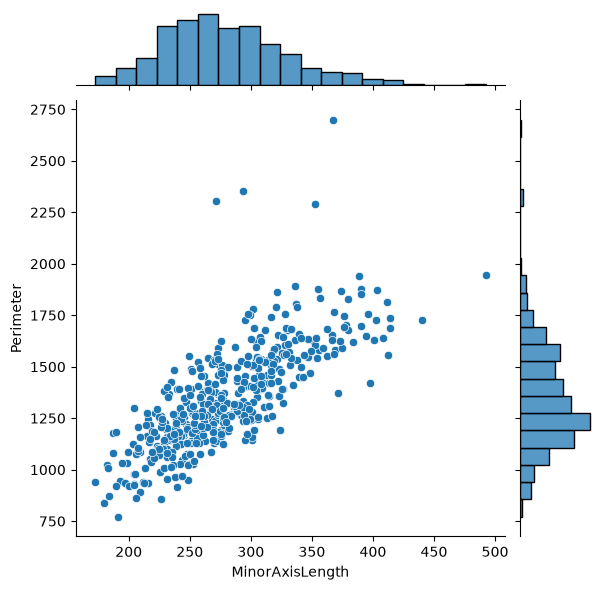

In [620]:
sns.jointplot(data=X[y == 'Besni'], x="MinorAxisLength", y="Perimeter")

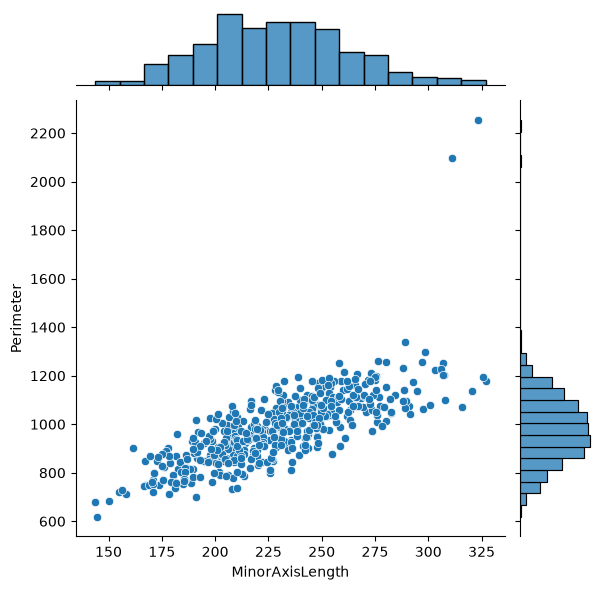

In [621]:
sns.jointplot(data=X[y == 'Kecimen'], x="MinorAxisLength", y="Perimeter")

In [622]:
_x = np.linspace(0, 800, 200)
_y = np.linspace(0, 2000, 500)

_X,_Y = np.meshgrid(_x,_y)
_pos = np.dstack((_X,_Y))

besni_dist = multivariate_normal(
    mean=mean_besni_features,
    cov=cov_besni_features
)

kecimen_dist = multivariate_normal(
    mean=mean_kecimen_features,
    cov=cov_kecimen_features
)

Z_besni = besni_dist.pdf(_pos)
Z_kecimen = kecimen_dist.pdf(_pos)


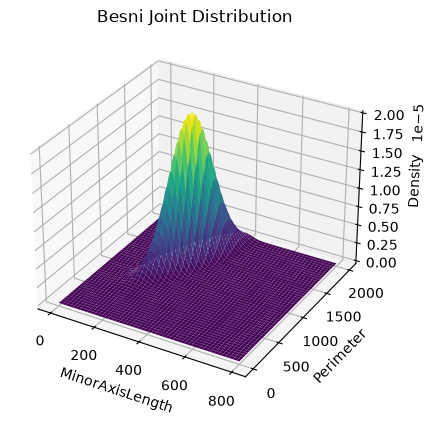

In [623]:
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(_X,_Y, Z_besni, cmap="viridis")

ax.set_xlabel("MinorAxisLength")
ax.set_ylabel("Perimeter")
ax.set_zlabel("Density")
ax.set_title("Besni Joint Distribution")

plt.show()

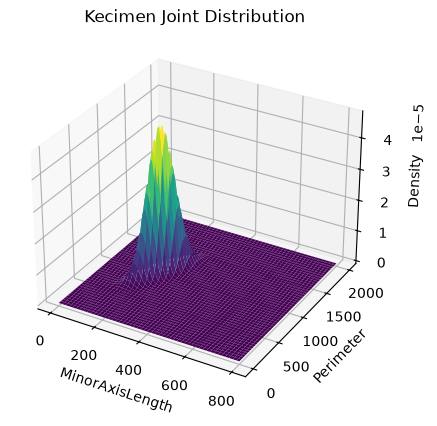

In [624]:
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(_X, _Y, Z_kecimen, cmap="viridis")

ax.set_xlabel("MinorAxisLength")
ax.set_ylabel("Perimeter")
ax.set_zlabel("Density")
ax.set_title("Kecimen Joint Distribution")

plt.show()

Yes. Under the assumed joint multivariate-normal model, each marginal variable is also normally distributed, which is consistent with the bell-shaped marginal distributions.

6. Given your answer to Question 3, write the functional form of the likelihood ratio. You may
define notation for the mean and covariance of each class.

- $\mu_K,\Sigma_K$: mean vector and covariance matrix for Class 0
- $\mu_B,\Sigma_B$: mean vector and covariance matrix for Class 1
- $x$: an observation
- $d$: number of input attributes


Becuase both are multivariate normal, their densities are:
$$
p(x\mid C_i)
=
\frac{1}
{(2\pi)^{d/2}|\Sigma_i|^{1/2}}
\exp\left[
-\frac{1}{2}(x-\mu_i)^T
\Sigma_i^{-1}
(x-\mu_i)
\right]
$$

So the liklihood ratio is:

$$
\Lambda(x)
=
\frac{p(x\mid C_B)}{p(x\mid C_K)}
$$

Substituting the multivariate normal densities:

$$
\Lambda(x)
=
\frac{
\frac{1}{(2\pi)^{d/2}|\Sigma_B|^{1/2}}
\exp\left[
-\frac{1}{2}(x-\mu_B)^T\Sigma_B^{-1}(x-\mu_B)
\right]
}{
\frac{1}{(2\pi)^{d/2}|\Sigma_K|^{1/2}}
\exp\left[
-\frac{1}{2}(x-\mu_K)^T\Sigma_K^{-1}(x-\mu_K)
\right]
}
$$

simplifing

$$
\Lambda(x)
=
\frac{|\Sigma_K|^{1/2}}{|\Sigma_B|^{1/2}}
\exp\left[
-\frac{1}{2}(x-\mu_B)^T\Sigma_B^{-1}(x-\mu_B)
+
\frac{1}{2}(x-\mu_K)^T\Sigma_K^{-1}(x-\mu_K)
\right]
$$

7. Given your answers to Questions 3 and 6, write the discriminant function for each class. Then,
calculate the discriminant functions for each sample point and label each of them with the class
name. (Hint: see Eq. (4.20) in the textbook. The “label” here is based on your calculated
discriminant. You may store the labels in an Excel or .csv file.) 

$$
g_i(x)
=
\log p(x|C_i)+\log P(C_i)
$$

For Kecimen:

$$
g_K(x)
=
\log p(x|C_K)+\log P(C_K)
$$

For Besni:

$$
g_B(x)
=
\log p(x|C_B)+\log P(C_B)
$$

**Classification**

$$
g_K(x) > g_B(x)
\quad \Rightarrow \quad
x \in C_K
$$

$$
g_B(x) > g_K(x)
\quad \Rightarrow \quad
x \in C_B
$$

In [625]:
class Classifier():
    def __init__(self, pooled=False):
        self.pooled = pooled

    def fit(self, X, y):
        self.mean_besni = X[y == 'Besni'].mean().to_numpy()
        self.mean_kecimen = X[y == 'Kecimen'].mean().to_numpy()

        self.cov_besni = np.cov(X[y == 'Besni'].to_numpy(), rowvar=False)
        self.cov_kecimen = np.cov(X[y == 'Kecimen'].to_numpy(), rowvar=False)

        self.prior_besni = (y == 'Besni').mean()
        self.prior_kecimen = (y == 'Kecimen').mean()

        if self.pooled:
            self.pooled_cov = (
                self.cov_besni * self.prior_besni
                + self.cov_kecimen * self.prior_kecimen
            )

        return self

    def __discriminant(self, x, mean, cov, prior):
        diff = x - mean

        sol = np.linalg.solve(cov, diff)

        maha = diff.T @ sol

        sign, logdet = np.linalg.slogdet(cov)

        return (
            -0.5 * logdet
            -0.5 * maha
            + np.log(prior)
        )

    def discriminant_Besni(self, x):
        cov = self.pooled_cov if self.pooled else self.cov_besni

        return self.__discriminant(
            x,
            self.mean_besni,
            cov,
            self.prior_besni
        )

    def discriminant_Kecimen(self, x):
        cov = self.pooled_cov if self.pooled else self.cov_kecimen

        return self.__discriminant(
            x,
            self.mean_kecimen,
            cov,
            self.prior_kecimen
        )

    def classify(self, x):
        if self.discriminant_Besni(x) > self.discriminant_Kecimen(x):
            return 'Besni'
        else:
            return 'Kecimen'

    def predict(self, X):
        return np.array([
            self.classify(x)
            for x in X.to_numpy()
        ])

    def score(self, X, y):
        predictions = self.predict(X)
        return (
            accuracy_score(y, predictions),
            confusion_matrix(
                y,
                predictions,
                labels=['Kecimen', 'Besni']
            )
        )

In [626]:
classify = Classifier(pooled=False)
classify.fit(X,y)
predictions = classify.predict(X)
acc, cm = classify.score(X,y)

8. Given your answers to Questions 3 and 6, use a pooled covariance matrix for all classes and
write the discriminant function for each class. Then, calculate the discriminant functions for each
sample point and label each of them with the class name. (Hint: see Eqs. (5.21) and (5.22) in the
textbook. The “label” here is based on your calculated discriminant. You may store the labels in
an Excel or .csv file.) 

In [627]:
classify_pooled = Classifier(pooled=True)
classify_pooled.fit(X,y)
predictions_pooled = classify_pooled.predict(X)
acc_pooled, cm_pooled = classify_pooled.score(X,y)

9. Use a confusion matrix to show the classification results obtained using the discriminant
functions in Questions 7 and 8. Calculate the classification accuracy for both and compare the
results. Briefly describe your findings. (Hint: you will obtain two confusion matrices: one for the
results from Question 7 and one for the results from Question 8.) 

Accuracy: 0.86
Accuracy Pooled: 0.86


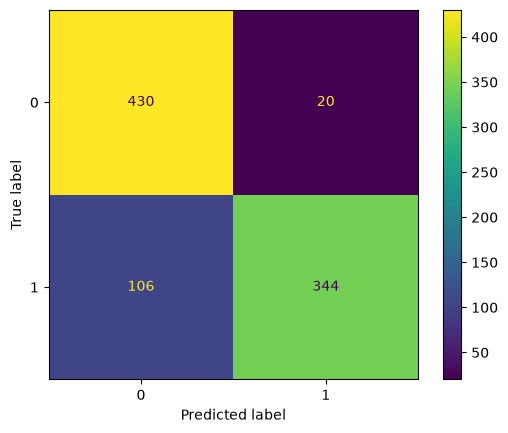

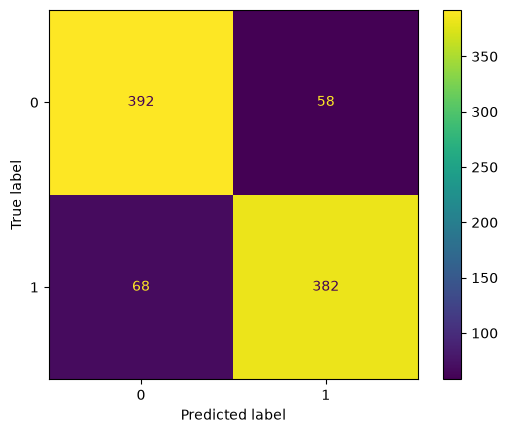

In [628]:
ConfusionMatrixDisplay(cm).plot()
ConfusionMatrixDisplay(cm_pooled).plot()

print(f"Accuracy: {round(acc, 3)}")
print(f"Accuracy Pooled: {round(acc_pooled, 3)}")

Both classifiers achieved 0.860 accuracy, but the separate-covariance model performed better on Kecimen while the pooled model performed better on Besni.

## Part 2

Do 5-fold cross-validation for the dataset and perform classification analysis. For each of the five folds, do the following:

1. Assume that the input attributes are multivariate normal. Calculate the mean vector and covariance
matrix for the input attributes in each class using the training data. (10 pts)
2. Given your answer to Question 1, calculate the discriminant function for the testing data. Then label each
testing sample with the class name. Finally, create a confusion matrix to show the classification results for
the testing data. (Hint: You may store the labels in an Excel or .csv file.)
3. Given your answer to Question 1, use a pooled covariance matrix for all classes and calculate the
discriminant function for the testing data. Then label each testing sample with the class name. Finally, create
a confusion matrix to show the classification results for the testing data. (Hint: You may store the labels in
an Excel or .csv file.)
4. For the discriminant functions in Questions 2 and 3, respectively, calculate the average false positive
rate, false negative rate, true positive rate, and true negative rate for the classification results across the
five folds. (Hint: you will get four rates for each classification method.)



In [629]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

pooled_cm = []
non_pooled_cm = []

pooled_acc = []
non_pooled_acc = []

for fold, (train_index, test_index) in enumerate(kf.split(X,y)):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    classify.fit(X_train, y_train)
    predictions = classify.predict(X_test)
    acc, cm = classify.score(X_test, y_test)

    classify_pooled.fit(X_train, y_train)
    predictions_pooled = classify_pooled.predict(X_test)
    acc_pooled, cm_pooled = classify_pooled.score(X_test, y_test)

    pooled_cm.append(cm_pooled)
    non_pooled_cm.append(cm)

    pooled_acc.append(acc_pooled)
    non_pooled_acc.append(acc)

def get_rates(cm):
    tn, fp, fn, tp = cm.ravel()

    tpr = tp / (tp + fn)
    fnr = fn / (tp + fn)
    tnr = tn / (tn + fp)
    fpr = fp / (tn + fp)

    return tpr, fnr, tnr, fpr

pooled_rates = np.array([get_rates(cm) for cm in pooled_cm])
non_pooled_rates = np.array([get_rates(cm) for cm in non_pooled_cm])

print("Non-Pooled Average:")
print("TPR, FNR, TNR, FPR:", non_pooled_rates.mean(axis=0))

print("Pooled Average:")
print("TPR, FNR, TNR, FPR:", pooled_rates.mean(axis=0))

print("Non-Pooled Accuracy:", np.mean(non_pooled_acc))
print("Pooled Accuracy:", np.mean(pooled_acc))


Non-Pooled Average:
TPR, FNR, TNR, FPR: [0.75560489 0.24439511 0.9468108  0.0531892 ]
Pooled Average:
TPR, FNR, TNR, FPR: [0.84797166 0.15202834 0.86974649 0.13025351]
Non-Pooled Accuracy: 0.85
Pooled Accuracy: 0.857777777777778


5. Briefly describe the performance of each discrimination method and identify the best one for this dataset
based on the average performance across the five folds of cross-validation. (5 pts)

The non-pooled method has a higher TPR but lower accuracy and TNR. While the pooled method has a lower TPR, it has a higher TNR, meaning it performs better at correctly classifying the second class. Overall, the pooled covariance method performed better because it achieved higher accuracy and more balanced performance across the two classes.

## Part 3

1. Visualize “Perimeter” against each independent variable and describe the trends and patterns in your
plots. (Hint: you will get 6 plots, each with “Perimeter” as the vertical axis and an independent variable as
the horizontal axis.) 

In [630]:
features = ['Area', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'ConvexArea', 'Extent']

y = df["Perimeter"]
X = df[features]
combined = pd.concat([X, y], axis=1)

combined.describe()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,Extent,Perimeter
count,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000,900.000000
mean,87804.127778,430.929950,254.488133,0.781542,91186.090000,0.699508,1165.906636
std,39002.111390,116.035121,49.988902,0.090318,40769.290132,0.053468,273.764315
min,25387.000000,225.629541,143.710872,0.348730,26139.000000,0.379856,619.074000
25%,59348.000000,345.442898,219.111126,0.741766,61513.250000,0.670869,966.410750
50%,78902.000000,407.803951,247.848409,0.798846,81651.000000,0.707367,1119.509000
75%,105028.250000,494.187014,279.888575,0.842571,108375.750000,0.734991,1308.389750
max,235047.000000,997.291941,492.275279,0.962124,278217.000000,0.835455,2697.753000


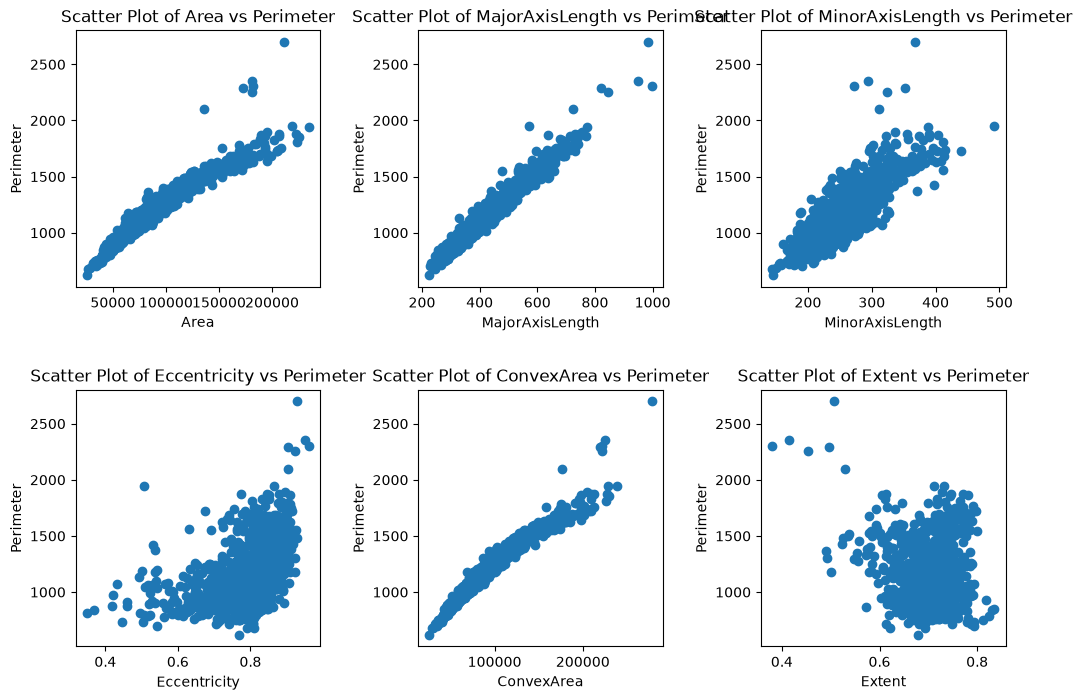

In [631]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(12, 8))
plt.subplots_adjust(hspace=0.4, wspace=0.4)

for i, feature in enumerate(features):
    ax = axes[i // 3, i % 3]
    ax.scatter(data=combined, x=feature, y="Perimeter")
    ax.set_title(f'Scatter Plot of {feature} vs Perimeter')
    ax.set_xlabel(feature)
    ax.set_ylabel('Perimeter')

plt.show()
    

Area, MajorAxisLength, MinorAxisLength, and ConvexArea show clear positive relationships with Perimeter, with larger values generally corresponding to a larger perimeter. Eccentricity shows a weaker positive relationship, while Extent has little clear relationship with Perimeter.

2. Use the first 700 samples in the dataset as the training data and the rest as the testing data. Calculate the
correlation matrix for the dependent and independent variables for the training data. Based on the
correlation matrix, identify which independent variables have a major association with the dependent
variable. Does this association imply a causal relationship? Why or why not? (Hint: Save the correlations
in an Excel or .csv file.) 

In [632]:
X_train = X[:700]
X_test = X[700:]

y_train = y[:700]
y_test = y[700:]

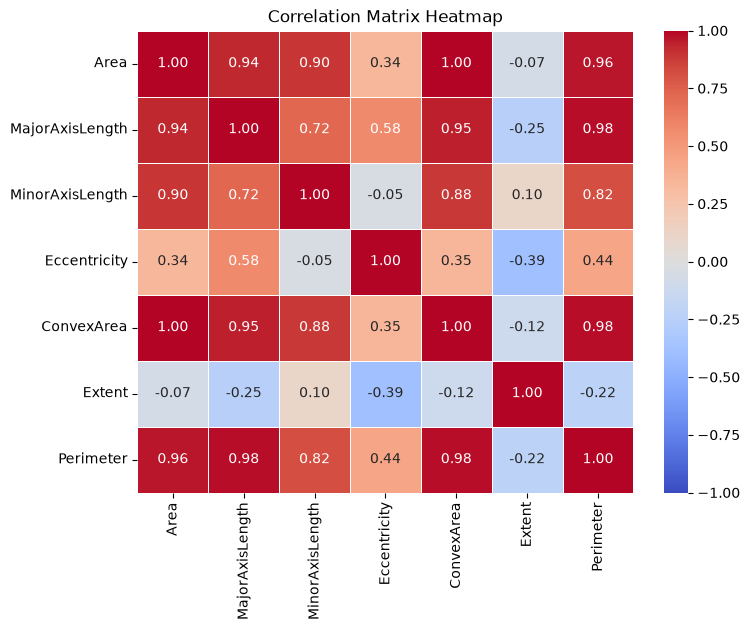

In [633]:
combined_train = pd.concat([X_train, y_train], axis=1)
corr_matrix = combined_train.corr()

plt.figure(figsize=(8, 6))
corr_matrix.to_csv("correlation_matrix.csv")

# Plot the heatmap
sns.heatmap(
    corr_matrix, 
    annot=True,          
    cmap='coolwarm',     
    vmin=-1, vmax=1,     
    fmt=".2f",           
    linewidths=0.5       
)

plt.title('Correlation Matrix Heatmap')
plt.show()


Area, MajorAxisLength, MinorAxisLength, and ConvexArea have the strongest associations with Perimeter based on the correlation matrix. However, these correlations do not imply causation because correlation only measures the strength of association between variables and does not establish that one causes another.

3. Use Python to fit a linear regression model using the training data. Summarize the model coefficients.
Based on the coefficients, which independent variables appear to have a greater impact on the dependent
variable? 

In [634]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Coefficients: {model.coef_}")

Coefficients: [-7.74061811e-03  1.80314951e+00  1.60482520e+00 -1.12092167e-03
  7.32444270e-03 -6.71396735e-04]


MajorAxisLength and MinorAxisLength have the largest raw coefficients, but because the predictors are measured on different scales, coefficient magnitude alone cannot reliably determine which variable has the greatest impact.

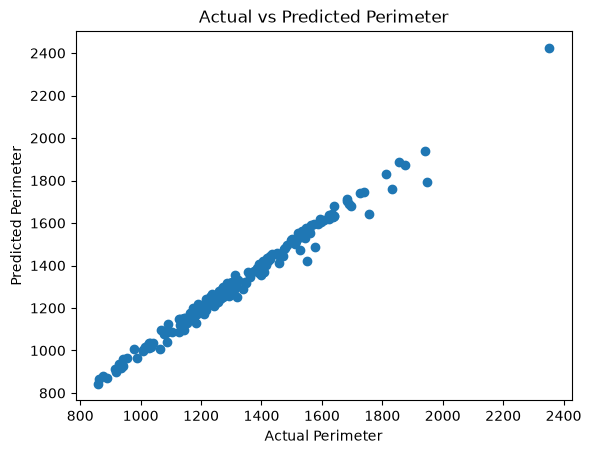

min perimeter: 619.074
max perimeter: 2697.753
mean squared error: 748.9708174329713
r-squared: 0.9866238623941354


In [635]:
plt.scatter(y_test, y_pred)
plt.xlabel('Actual Perimeter')
plt.ylabel('Predicted Perimeter')
plt.title('Actual vs Predicted Perimeter')
plt.show()

print(f'min perimeter: {y.min()}')
print(f'max perimeter: {y.max()}')
print(f'mean squared error: {mean_squared_error(y_test, y_pred)}')
print(f'r-squared: {r2_score(y_test, y_pred)}')

The model has good predictive performance, with an r-squared of 0.987 and an MSE of 748.97. The predictions closely follow the true Perimeter values, although a few larger errors are present.

5. Based on the results from Question 3, do you think that the independent variables are mutually linearly
independent? What are the effects of linear dependence among the independent variables on the fitted linear
regression model? 

The independent variables are likely not fully linearly independent because some contain overlapping information about the size and shape of the raisins. This multicollinearity can make individual regression coefficients unstable, although the relatively low MSE suggests it does not significantly hurt prediction performance.

6. Perform principal component analysis (PCA) on the training data matrix of independent variables. Show
the variance explained by each principal component.

In [636]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA()
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

Explained variance ratio:
[6.43096815e-01 2.41722118e-01 1.03338830e-01 9.01056333e-03
 2.31438398e-03 5.17289781e-04]


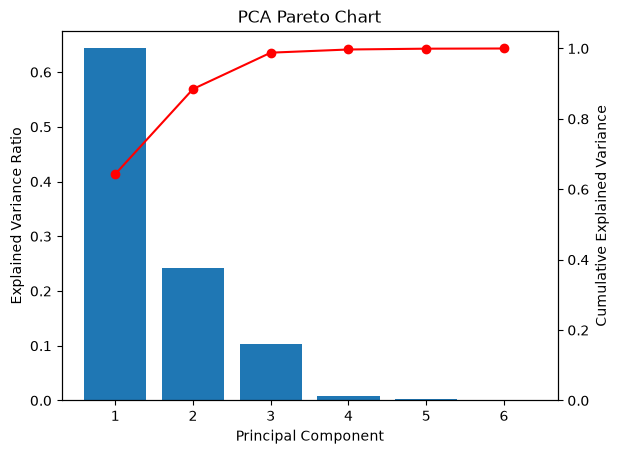

In [637]:
variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(variance)

components = range(1, len(variance) + 1)

fig, ax1 = plt.subplots()

ax1.bar(components, variance)
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Explained Variance Ratio")
ax1.set_xticks(components)

ax2 = ax1.twinx()
ax2.plot(components, cumulative_variance, marker="o", color='red')
ax2.set_ylabel("Cumulative Explained Variance")
ax2.set_ylim(0, 1.05)

plt.title("PCA Pareto Chart")
plt.show()

8. Take the first four principal components from Question 7 and fit a multivariate regression model. Use
the model to make predictions for the testing samples and calculate the mean squared error. (Hint: You
need to transform the testing data to principal components as well.)

mean squared error: 1866.297041599166
r-squared: 0.9666691338823991


Text(0.5, 0, 'Actual Perimeter')

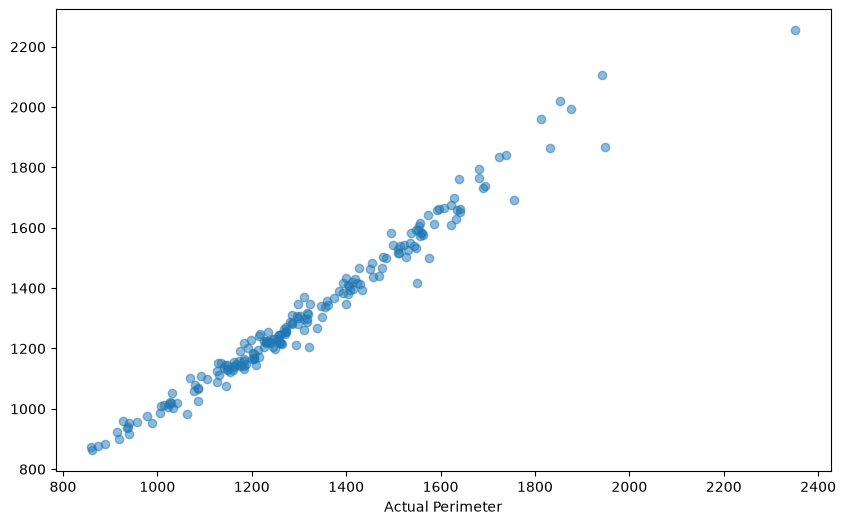

In [638]:
X_train_pca_4 = X_train_pca[:, :4]
X_test_pca_4 = X_test_pca[:, :4]

model_pca = LinearRegression()
model_pca.fit(X_train_pca_4, y_train)
y_pred_pca = model_pca.predict(X_test_pca_4)

print(f'mean squared error: {mean_squared_error(y_test, y_pred_pca)}')
print(f'r-squared: {r2_score(y_test, y_pred_pca)}')

plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_pca, alpha=0.5)
plt.xlabel('Actual Perimeter')

9. Give a practical scenario in which you would use principal component analysis to reduce the data
dimensionality before fitting a regression model; give a practical scenario in which you would not use
principal component analysis to reduce the data dimensionality before fitting a regression model. (Hint:
you can name any data source or situation that is not necessarily related to the Raisin dataset.)

A practical use of PCA would be regression on a high-dimensional dataset with many correlated or redundant features, where multicollinearity could make the regression unstable. I would not use PCA when the original variables are individually meaningful and interpreting how each variable affects the prediction is important, since PCA combines the original variables into principal components.